# Convolutional Autoencoder
### Learning to reconstruct crop imagery with PyTorch

**Image reconstruction · Representation learning · Encoder–decoder networks**

This notebook walks through a convolutional autoencoder experiment, from preparing crop images to inspecting reconstructed examples.

## Experiment overview

**Research question:** Can a convolutional encoder–decoder learn to reproduce crop images from a spatial feature representation?

The input image also serves as the reconstruction target, so crop labels are not used in the training objective. The encoder extracts features and reduces spatial resolution; the decoder maps those features back to image space.

| Recorded setting | Value |
| :--- | :--- |
| Training / test images | 211 / 46 |
| Image size | 224 × 224 pixels, three channels |
| Batch size | 16 |
| Training duration | 50 epochs |
| Optimizer | Adam, learning rate `0.0001` |
| Reconstruction objective | Mean absolute error (MAE) |

### Notebook roadmap

1. **Set up the environment** and connect the image dataset.
2. **Prepare the data** for minibatch training.
3. **Build the network** and inspect its feature shapes.
4. **Train and save** the reconstruction model.
5. **Inspect reconstructions** and discuss the experiment's limitations.

> **About the saved run:** The code and outputs below preserve the original experiment. The dataset and checkpoint are not included in this repository. A tensor-layout issue affects this run; the relevant sections explain the correction required before retraining.

## 1. Environment and dataset access

This notebook was originally run in Google Colab. Mount Google Drive below, then import the libraries used for image loading, tensor operations, training, and visualization.

**Before running:** supply an authorized image dataset and replace the absolute Drive paths in the loading, checkpoint-saving, and inference cells. For setup details, see the [reproduction guide](docs/REPRODUCIBILITY.md).

In [54]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [55]:
# Import packages
import polars as pl
import numpy as np
import os
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from tqdm import tqdm
from PIL import Image

## 2. Prepare the image data

### Inspect the source and load both splits

The first cell opens one example image and converts it to a NumPy array. The helper that follows loads the training and test folders, resizes each image to `224 × 224`, and scales pixel values to `[0, 1]`.

Expected folder structure:

```text
Crop Image Dataset/
├── crop_images/
│   └── <crop_category>/
│       └── <image>.jpeg
└── test_crop_image/
    └── <image file>
```

Training category folders organize the files; their names are not used as labels. The original loader assumes three-channel images and does not verify split overlap. A corrected run should explicitly convert images to RGB and document how the splits were created.

In [56]:
# Load the dataset
img = Image.open("/content/drive/MyDrive/Study/Computer Science/Project/Autoencoder/Convolution Autoencoder/Crop Image Dataset/crop_images/jute/jute001a.jpeg")
test = np.asarray(img)

In [57]:
# Construct train and test data
def construct_img_array(image_dir_path, type):
  list_pixel_values = []
  if type == 'train':
    for crop_dir in os.listdir(image_dir_path):
      if "DS_Store" in crop_dir:
        continue
      for file in os.listdir(f"{image_dir_path}/{crop_dir}"):
        if not file.endswith(".jpeg"):
          continue
        img = Image.open(f"{image_dir_path}/{crop_dir}/{file}").resize((224, 224))
        img_array = np.asarray(img)/255. # Resizing
        list_pixel_values.append(img_array)
  else:  # test
    for file in os.listdir(image_dir_path):
      if ".ipynb" in file:
          continue
      img = Image.open(f"{image_dir_path}/{file}").resize((224, 224))
      img_array = np.asarray(img)/255. # Resizing
      list_pixel_values.append(img_array)

  return np.array(list_pixel_values)

In [58]:
train_data = construct_img_array("/content/drive/MyDrive/Study/Computer Science/Project/Autoencoder/Convolution Autoencoder/Crop Image Dataset/crop_images", "train")
test_data = construct_img_array("/content/drive/MyDrive/Study/Computer Science/Project/Autoencoder/Convolution Autoencoder/Crop Image Dataset/test_crop_image", "test")

print(f"Train data = {train_data.shape}")
print(f"Test data = {test_data.shape}")

Train data = (211, 224, 224, 3)
Test data = (46, 224, 224, 3)


### Prepare image tensors

The recorded dataset contains **211 training images** and **46 test images**, each resized to `224 × 224`. Dividing pixel values by 255 scales them to `[0, 1]`, matching the decoder's sigmoid output range.

NumPy stores the loaded images as `(N, H, W, C)`, while PyTorch convolution layers expect `(N, C, H, W)`.

> **Tensor-layout caveat:** The original cell below uses `reshape`, which changes the shape without reordering the channel axis. A corrected run must use `permute(0, 3, 1, 2).contiguous()` after conversion to a float tensor. Apply the corresponding correction during visualization and retrain before evaluating the corrected pipeline.

In [59]:
# Convert data into tensor
train_data = torch.from_numpy(train_data).to(torch.float)
test_data = torch.from_numpy(test_data).to(torch.float)

# Reshape data shape
train_data = torch.reshape(train_data, (
    train_data.size()[0],
    train_data.size()[3],
    train_data.size()[1],
    train_data.size()[2]
))
test_data = torch.reshape(test_data, (
    test_data.size()[0],
    test_data.size()[3],
    test_data.size()[1],
    test_data.size()[2]
))
print(f"Training data size = {train_data.size()}")
print(f"Testting data size = {test_data.size()}")

Training data size = torch.Size([211, 3, 224, 224])
Testting data size = torch.Size([46, 3, 224, 224])


### Create training batches

A `DataLoader` groups images into batches of **16** and shuffles their order for each training pass. Each image is both the model input and its target, so a separate label tensor is unnecessary.

With 211 training images, each epoch has 13 full batches and a final batch of 3 images.

In [60]:
# Dataloader
from torch.utils.data import DataLoader
data_loader_train = DataLoader(train_data, batch_size=16, shuffle=True)

## 3. Build the encoder–decoder

The network combines two modules:

- **Encoder:** two strided convolutions extract features while reducing width and height.
- **Decoder:** two transposed convolutions restore the original spatial size. A final sigmoid constrains reconstructed values to `[0, 1]`.

`FullNetwork` connects these modules into a single reconstruction model.

| Stage | Operation | Output shape per image |
| :--- | :--- | :--- |
| Input | Normalized image tensor | `3 × 224 × 224` |
| Encoder 1 | 3 × 3 convolution, stride 2, padding 1 + ReLU | `64 × 112 × 112` |
| Encoder 2 | 3 × 3 convolution, stride 2, padding 1 | `256 × 56 × 56` |
| Decoder 1 | 4 × 4 transposed convolution, stride 2, padding 1 + ReLU | `64 × 112 × 112` |
| Decoder 2 | 4 × 4 transposed convolution, stride 2, padding 1 + sigmoid | `3 × 224 × 224` |

> **Spatial downsampling vs. compression:** The encoded representation contains 802,816 values, compared with 150,528 input values—about **5.33× more elements**. This network reduces spatial resolution, but does not provide a smaller representation by total element count.

In [69]:
class Encoder(nn.Module):
    def __init__(self, input_channels):
        super(Encoder, self).__init__()
        self.enc_conv_1 = nn.Conv2d(input_channels, 64, kernel_size=3, stride=2, padding=1)
        self.enc_conv_2 = nn.Conv2d(64, 256, kernel_size=3, stride=2, padding=1)
        self.enc_relu = nn.ReLU()

    def forward(self, input_data):
        output = self.enc_conv_1(input_data)
        output = self.enc_relu(output)
        output = self.enc_conv_2(output)
        return output

class Decoder(nn.Module):
    def __init__(self, input_channels):
        super(Decoder, self).__init__()
        self.dec_conv_1 = nn.ConvTranspose2d(256, 64, kernel_size=4, stride=2, padding=1)
        self.dec_conv_2 = nn.ConvTranspose2d(64, input_channels, kernel_size=4, stride=2, padding=1)
        self.dec_relu = nn.ReLU()
        self.dec_sigmoid = nn.Sigmoid()

    def forward(self, input_data):
        output = self.dec_conv_1(input_data)
        output = self.dec_relu(output)
        output = self.dec_conv_2(output)
        output = self.dec_sigmoid(output)
        return output

class FullNetwork(nn.Module):
    def __init__(self, input_channels):
        super(FullNetwork, self).__init__()
        self.encoder = Encoder(input_channels)
        self.decoder = Decoder(input_channels)

    def forward(self, input_data):
        output = self.encoder(input_data)
        output = self.decoder(output)
        return output

In [75]:
model = FullNetwork(train_data.size()[1])
model

FullNetwork(
  (encoder): Encoder(
    (enc_conv_1): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (enc_conv_2): Conv2d(64, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (enc_relu): ReLU()
  )
  (decoder): Decoder(
    (dec_conv_1): ConvTranspose2d(256, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (dec_conv_2): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (dec_relu): ReLU()
    (dec_sigmoid): Sigmoid()
  )
)

## 4. Train the reconstruction model

### Objective and optimizer

Training minimizes the **mean absolute error (MAE)** between the reconstructed image and its input. PyTorch's `nn.L1Loss()` averages absolute pixel-value differences over the batch, channels, and spatial dimensions.

$$
\mathcal{L}_{\mathrm{MAE}} = \frac{1}{M} \sum_{i=1}^{M} |\hat{x}_i - x_i|
$$

Here, $x_i$ is an input value, $\hat{x}_i$ is its reconstruction, and $M$ is the number of compared values. **Adam** updates the model parameters with a learning rate of `0.0001`.

### Reading the training loop

For each batch, the model reconstructs the input, computes the loss, clears previous gradients, backpropagates, and updates its parameters.

> **Logging detail:** The loop records only the **last batch's MAE** after each epoch. The curve is neither an epoch-average training loss nor a test metric. Because batches are shuffled, the three images in the last batch can change between epochs.

In [76]:
# Optimizer and loss function
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
loss_fn = nn.L1Loss()

In [77]:
# Training autoencoder model
import time
def train_model(total_epoch):
    list_loss_value = []
    for epoch in range(total_epoch):
        print(f"Epoch {epoch+1}")
        for x_batch in tqdm(data_loader_train):
            result = model.forward(x_batch)
            loss = loss_fn(result, x_batch)

            # Back propagation
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        print(f"Loss for epoch {epoch+1} = {loss}\n")
        loss_detach = loss.detach().to('cpu').numpy()
        list_loss_value.append(loss_detach)

    plt.plot(list(range(1, total_epoch+1)), list_loss_value, color='green')
    plt.xlabel("Epoch")
    plt.ylabel("MAE Loss")
    plt.title("Reconstruction Loss", fontweight='bold')

Epoch 1


100%|██████████| 14/14 [00:56<00:00,  4.02s/it]


Loss for epoch 1 = 0.18653662502765656

Epoch 2


100%|██████████| 14/14 [00:56<00:00,  4.05s/it]


Loss for epoch 2 = 0.20626026391983032

Epoch 3


100%|██████████| 14/14 [00:56<00:00,  4.05s/it]


... (91 outputs left out)

100%|██████████| 14/14 [00:57<00:00,  4.12s/it]


Loss for epoch 49 = 0.045697420835494995

Epoch 50


100%|██████████| 14/14 [00:57<00:00,  4.14s/it]

Loss for epoch 50 = 0.06701188534498215



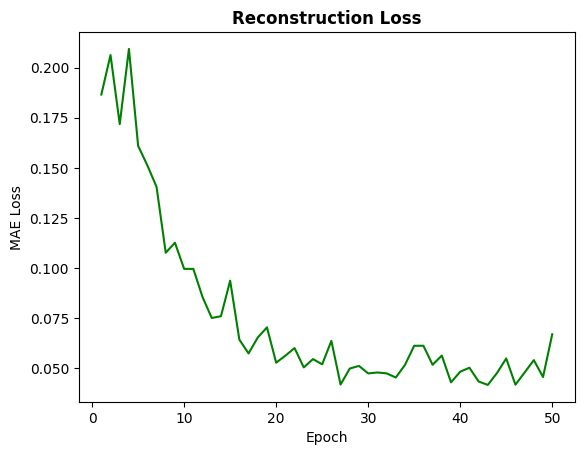

In [78]:
train_model(50)

### Interpret the recorded loss

The saved logs show an overall decrease in last-batch reconstruction error:

| Observation | Last-batch MAE |
| :--- | ---: |
| Epoch 1 | 0.18654 |
| Lowest recorded value — epoch 43 | 0.04176 |
| Final epoch — epoch 50 | 0.06701 |

This trend is consistent with learning the training objective. It does not establish generalization or reconstruction quality across the full test set, especially given the tensor-layout issue.

### Save the final checkpoint

The next cell saves the model's parameter dictionary to Google Drive. It stores the **final epoch's parameters**; the training loop does not select a checkpoint using validation performance.

In [83]:
# Save model
torch.save(model.state_dict(), '/content/drive/MyDrive/Study/Computer Science/Project/Autoencoder/Convolution Autoencoder/rgb_test.pt')

## 5. Inspect test-image reconstructions

The inference function reloads the saved parameters, switches the model to evaluation mode, and moves it to **CPU**. It prints the encoder and decoder output shapes, then displays the input beside its reconstruction.

The examples use indices `1`, `22`, and `30` from the designated test array. They provide a qualitative inspection of three samples; no aggregate test metric is computed.

> **Implementation notes:** The training code does not explicitly transfer the model or batches to CUDA, so GPU training is not established. For a corrected inference workflow, load the checkpoint with the appropriate `map_location`, use `torch.inference_mode()`, and convert CHW tensors for display with `permute(1, 2, 0)` rather than `reshape`.

In [84]:
def inference(model,
              sample_image):
  # Load model's parameters
  model.load_state_dict(torch.load('/content/drive/MyDrive/Study/Computer Science/Project/Autoencoder/Convolution Autoencoder/rgb_test.pt', weights_only=True))

  # Evaluation process
  model.eval()
  model = model.to('cpu')
  encoder_output = model.encoder.forward(sample_image)
  print(f"The latent vector (encoder output) shape = {encoder_output.size()}")
  decoder_output = model.decoder.forward(encoder_output)
  print(f"The decoder output shape = {decoder_output.size()}")
  print("\n")

  # Visualize the output of decoder and original image
  sample_image = sample_image.numpy().reshape(
      sample_image.size()[1],
      sample_image.size()[2],
      sample_image.size()[0]
  )
  decoder_output = decoder_output.detach().numpy().reshape(
      decoder_output.size()[1],
      decoder_output.size()[2],
      decoder_output.size()[0]
  )
  fig, ax = plt.subplots(1,2)
  ax[0].imshow(sample_image)
  ax[0].set_title("Original Image", fontweight='bold')
  ax[1].imshow(decoder_output)
  ax[1].set_title("Decoder Output", fontweight='bold')

The latent vector (encoder output) shape = torch.Size([256, 56, 56])
The decoder output shape = torch.Size([3, 224, 224])


The latent vector (encoder output) shape = torch.Size([256, 56, 56])
The decoder output shape = torch.Size([3, 224, 224])


The latent vector (encoder output) shape = torch.Size([256, 56, 56])
The decoder output shape = torch.Size([3, 224, 224])




(None, None, None)

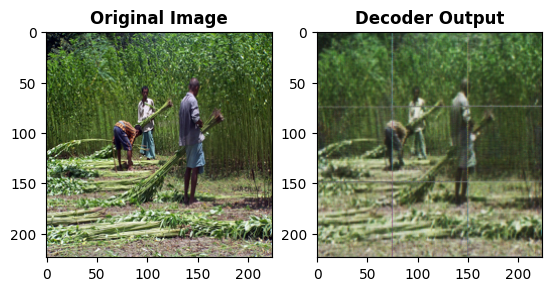

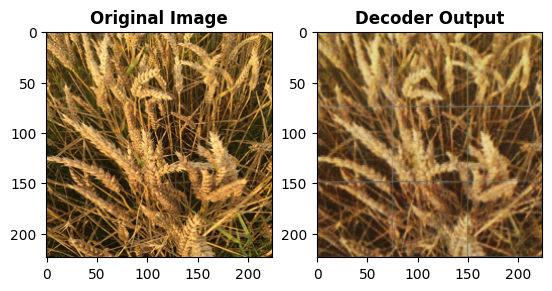

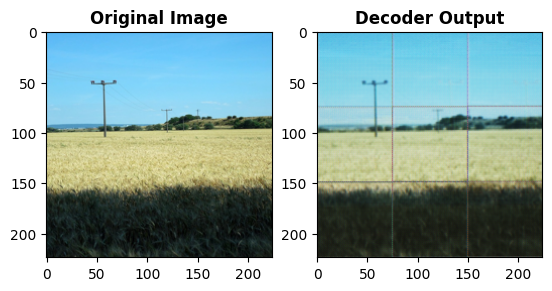

In [87]:
inference(model, test_data[1]), inference(model, test_data[22]), inference(model, test_data[30])

## 6. Findings and next experiments

### What the saved examples show

The displayed reconstructions retain broad scene layouts and colors, while fine textures and boundaries appear softer. Grid artifacts are also visible, particularly in the open-field example.

These observations describe the **original saved outputs**. The tensor-layout issue prevents them from validating reconstruction quality under a correctly arranged RGB pipeline. The experiment also does not establish image compression or full-test generalization.

### Improve the next run

1. **Correct image handling:** enforce RGB loading, use axis permutations, sort filenames, and verify image display before training.
2. **Make training reproducible:** centralize paths, record dataset provenance and library versions, and set random seeds.
3. **Strengthen evaluation:** use a separate validation split, log sample-weighted epoch losses, and save the best validation checkpoint.
4. **Measure fidelity:** evaluate the full test split with MAE, PSNR, and SSIM alongside representative visual comparisons.
5. **Explore the architecture:** compare a smaller feature bottleneck and alternative decoder designs after correcting the pipeline.

### Continue exploring

- [Experiment analysis](docs/EXPERIMENT_ANALYSIS.md) — evidence, technical caveats, and proposed improvements.
- [Reproduction guide](docs/REPRODUCIBILITY.md) — environment setup and corrected-workflow guidance.
- [Project overview](README.md) — architecture, recorded figures, and repository navigation.